1. IMPORT LIBRARY

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error

2. LOAD DATASET

In [49]:
file_path = "dataset/data_clean.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="surya_kaleng"
)

df.head()

,ds,y
0,2023-01-01,56
1,2023-01-02,95
2,2023-01-03,67
3,2023-01-04,76
4,2023-01-05,100


3. PREPRCESSING DATA

In [50]:
#Konversi Tanggal
df['ds'] = pd.to_datetime(df['ds'])

In [51]:
#urutkan data
df = df.sort_values('ds')

In [52]:
#cek missing value
df = df.sort_values('ds')
df = df.dropna()

In [53]:
#cek data duplikat
df.duplicated().sum()

0

In [54]:
#statistik deskriptif
df['y'].describe()

count    1092.000000
mean      117.001832
std        44.028592
min         0.000000
25%        90.000000
50%       110.000000
75%       144.000000
max       284.000000
Name: y, dtype: float64

4. VISUALISASI PENJUALAN

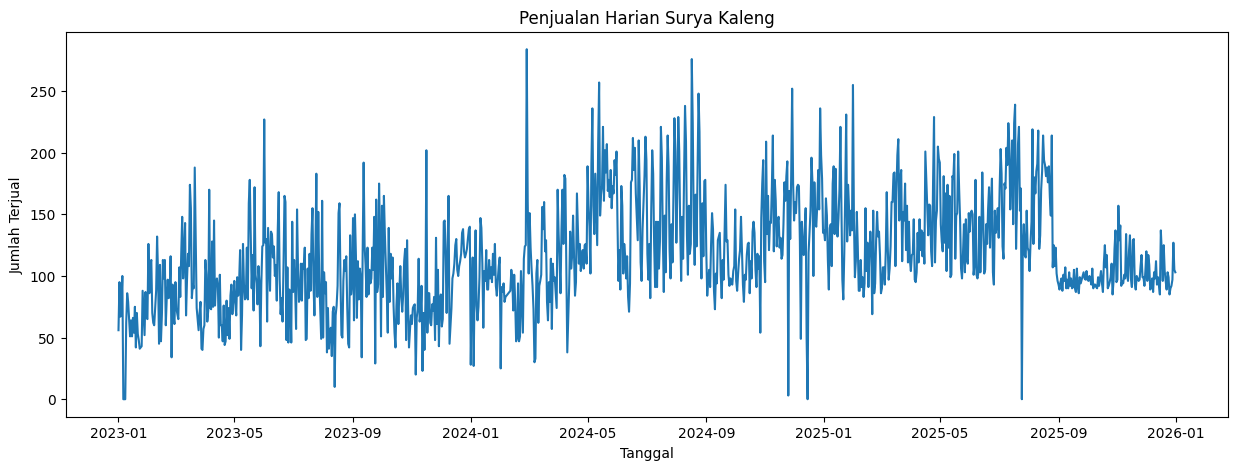

In [55]:
plt.figure(figsize=(15,5))

plt.plot(
    df['ds'],
    df['y']
)

plt.title("Penjualan Harian Surya Kaleng")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Terjual")

plt.show()

5. ANALISIS PERTAHUN

In [56]:
df['tahun'] = df['ds'].dt.year

df.groupby('tahun')['y'].mean()

tahun
2023     91.323288
2024    130.486188
2025    129.306849
Name: y, dtype: float64

6. SPLIT DATA

In [ ]:
train = df[
    df['ds'] < '2025-07-01'
]

test = df[
    df['ds'] >= '2025-07-01'
]

print("Train :", len(train))
print("Test :", len(test))

Train : 908
Test : 184


7. MEMBANGUN MODEL PROPHET

In [58]:
model = Prophet(
    changepoint_prior_scale=0.1,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model.fit(train)

14:44:58 - cmdstanpy - INFO - Chain [1] start processing
14:44:58 - cmdstanpy - INFO - Chain [1] done processing


8. PREDIKSI DATA TEST

In [59]:
future = model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

forecast = model.predict(future)
# print (forecast)

In [60]:
#AMBIL PREDIKISI DATA TEST
pred_test = forecast[
    ['ds','yhat']
]

pred_test = pred_test[
    pred_test['ds'].isin(
        test['ds']
    )
]
print (pred_test)

             ds        yhat
908  2025-07-01  135.204949
909  2025-07-02  139.532262
910  2025-07-03  136.437980
911  2025-07-04  142.307639
912  2025-07-05  137.300915
...         ...         ...
1087 2025-12-27  112.213573
1088 2025-12-28  103.454152
1089 2025-12-29  105.289882
1090 2025-12-30  104.734514
1091 2025-12-31  108.333078

[184 rows x 2 columns]


9. EVALUASI MODEL

In [61]:
evaluation = test.merge(
    pred_test,
    on='ds'
)

print (evaluation)
# evaluation.to_csv(
#     'hasil_evaluasi.csv',
#     index=False
# )


            ds    y  tahun        yhat
0   2025-07-01  131   2025  135.204949
1   2025-07-02  172   2025  139.532262
2   2025-07-03  203   2025  136.437980
3   2025-07-04  183   2025  142.307639
4   2025-07-05  124   2025  137.300915
..         ...  ...    ...         ...
179 2025-12-27   92   2025  112.213573
180 2025-12-28   97   2025  103.454152
181 2025-12-29  127   2025  105.289882
182 2025-12-30  105   2025  104.734514
183 2025-12-31  103   2025  108.333078

[184 rows x 4 columns]


In [62]:
mae = mean_absolute_error(
    evaluation['y'],
    evaluation['yhat']
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation['y'],
        evaluation['yhat']
    )
)

smape = np.mean(
    (2 * np.abs(evaluation['y'] - evaluation['yhat']))
    /
    ( np.abs(evaluation['y']) + np.abs(evaluation['yhat']))
) * 100

print("MAE :", round(mae))
print("RMSE :", round(rmse))
print("SMAPE :", round(smape,2), "%")

MAE : 23
RMSE : 34
SMAPE : 18.24 %


10. VISUALISASI AKTUAL VS PREDIKSI

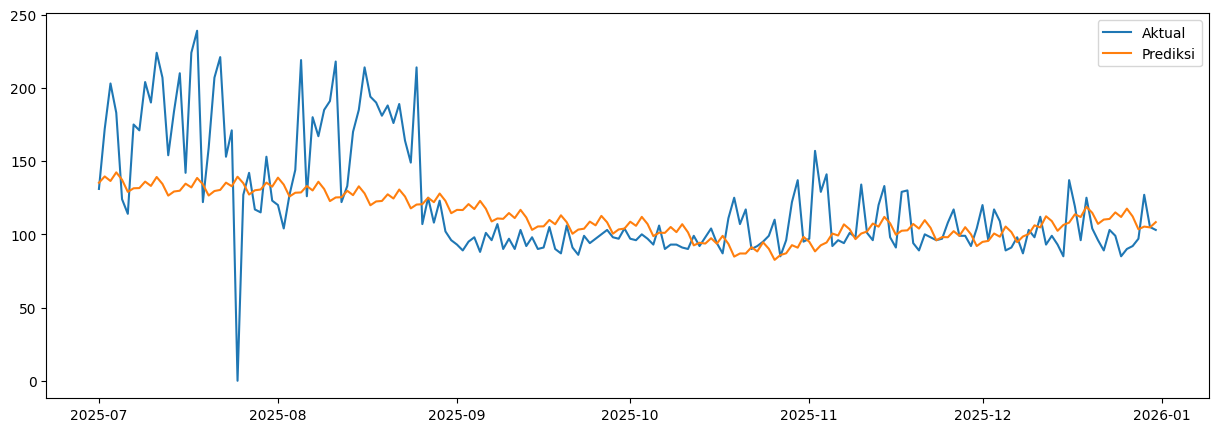

In [63]:
plt.figure(figsize=(15,5))

plt.plot(
    evaluation['ds'],
    evaluation['y'],
    label='Aktual'
)

plt.plot(
    evaluation['ds'],
    evaluation['yhat'],
    label='Prediksi'
)

plt.legend()

plt.show()

11. ANALISIS EROR TERBESAR

In [64]:
evaluation['error'] = abs(
    evaluation['y'] -
    evaluation['yhat']
)

evaluation.sort_values(
    'error',
    ascending=False
).head(20)

,ds,y,tahun,yhat,error
24,2025-07-25,0,2025,139.336530,139.336530
17,2025-07-18,239,2025,138.517146,100.482854
55,2025-08-25,214,2025,120.330351,93.669649
41,2025-08-11,218,2025,125.177854,92.822146
16,2025-07-17,224,2025,132.045116,91.954884
21,2025-07-22,221,2025,130.333579,90.666421
35,2025-08-05,219,2025,128.611773,90.388227
46,2025-08-16,214,2025,127.951396,86.048604
10,2025-07-11,224,2025,139.143126,84.856874
14,2025-07-15,210,2025,129.787210,80.212790


12. TRAINING FINAL MENGGUNAKAN SELURUH DATA

In [65]:
final_model = Prophet(
    changepoint_prior_scale=0.1,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

final_model.fit(df[['ds','y']])
print (final_model)

14:44:59 - cmdstanpy - INFO - Chain [1] start processing
14:44:59 - cmdstanpy - INFO - Chain [1] done processing


13. PERAMALAN 14 HARI KEDEPAN

In [66]:
future = final_model.make_future_dataframe(
    periods=14,
    freq='D'
)

forecast = final_model.predict(
    future
)

In [67]:
forecast_14 = forecast[
    ['ds','yhat']
].tail(14)

forecast_14
print (forecast_14)

             ds        yhat
1092 2026-01-01  106.332084
1093 2026-01-02  110.108695
1094 2026-01-03  105.266692
1095 2026-01-04   98.563987
1096 2026-01-05  102.070346
1097 2026-01-06  101.738021
1098 2026-01-07  104.463155
1099 2026-01-08  102.852227
1100 2026-01-09  107.141650
1101 2026-01-10  102.854810
1102 2026-01-11   96.732665
1103 2026-01-12  100.827442
1104 2026-01-13  101.073729
1105 2026-01-14  104.350340


14. HITUNG REKOMENDASI PEMBELIAN

In [68]:
total_forecast = round(
    forecast_14['yhat'].sum()
)

print(
    "Kebutuhan stok 14 hari:",
    total_forecast
)

Kebutuhan stok 14 hari: 1444


In [69]:
# SAFETY STOCK BERDASARKAN MAE
safety_stock = round(mae * 14)

# REKOMENDASI PERSEDIAAN
stok_beli = round(total_forecast +safety_stock)

print("Safety Stock:", safety_stock)

print("Rekomendasi pembelian:", stok_beli)

Safety Stock: 326
Rekomendasi pembelian: 1770
